# Online Shopping Purchase Prediction

A worked classification project using the Kaggle **Online Shoppers Intention** dataset.

**Question:** Can browsing activity identify sessions that end in a purchase?

**Observation:** one browsing session. **Target:** `Revenue`. **Main metric:** average precision (AP).

The workflow covers the objective, data checks, exploratory analysis, feature preparation,
individual models, tuning, stacking, evaluation and interpretation. Each model is fitted
directly in its own cell. Run the notebook from top to bottom from the `mock` directory.

## 1. Objective and evaluation

Predict purchases from session summaries. Purchases are the minority class, so accuracy
alone is insufficient. Select the model using **validation AP**, then select a cutoff
using validation F1. Report ROC-AUC, log loss, Brier score, precision and recall as well.

Reserve a final test set before exploring relationships. The validation set supports
both tuning and selection, so its winning score can be optimistic. Test results describe
this dataset and split; they do not establish performance on future visitors.

This is a retrospective session-scoring exercise. Duration, exit behavior and PageValues
may only be known late in a session. An early intervention model would need a clearly
defined prediction time and features available at that time.

## 2. Setup

Use pandas for preparation, matplotlib and seaborn for plots, and standard estimators
for modeling. Linear, nearest-neighbor and neural models use scaled inputs. Trees use
the same one-hot encoded features without scaling. Every figure is also saved as a PNG.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, log_loss, brier_score_loss,
    precision_score, recall_score, f1_score, accuracy_score,
    precision_recall_curve, roc_curve, ConfusionMatrixDisplay
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

os.makedirs("outputs/figures", exist_ok=True)
FIG = "outputs/figures/"
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 30)

## 3. Load and inspect the data

Check types, missing values, duplicate rows and target balance. The numerical codes for
operating system, browser, region and traffic type represent categories, not quantities.

Remove exact duplicate records before splitting. This prevents repeated identical
sessions from appearing in different partitions. It also changes the evaluation population
to distinct recorded profiles; identical summaries could represent different real sessions.
The source has no visitor identifier, so we cannot verify independence between visitors.

In [2]:
df = pd.read_csv("online_shoppers_intention.csv")
print("Original shape:", df.shape)
display(df.head())
df.info()
display(df.isna().sum().rename("Missing values"))
print("Exact duplicates:", df.duplicated().sum())

df = df.drop_duplicates().copy()
df["Revenue"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)
print("Shape after duplicate removal:", df.shape)
print("Remaining repeated feature profiles:", df.drop(columns="Revenue").duplicated().sum())
display(df["Revenue"].value_counts().rename("Sessions"))
display(df.describe().round(2))

Original shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
Name: Missing values, dtype: int64

Exact duplicates: 125
Shape after duplicate removal: (12205, 18)
Remaining repeated feature profiles: 0


Revenue
0    10297
1     1908
Name: Sessions, dtype: int64

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue
count,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00,12205.00
mean,2.34,81.65,0.51,34.83,32.05,1206.98,0.02,0.04,5.95,0.06,2.12,2.36,3.15,4.07,0.23,0.16
std,3.33,177.49,1.28,141.42,44.59,1919.60,0.05,0.05,18.65,0.20,0.91,1.71,2.40,4.02,0.42,0.36
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,8.00,193.00,0.00,0.01,0.00,0.00,2.00,2.00,1.00,2.00,0.00,0.00
50%,1.00,9.00,0.00,0.00,18.00,608.94,0.00,0.02,0.00,0.00,2.00,2.00,3.00,2.00,0.00,0.00
75%,4.00,94.70,0.00,0.00,38.00,1477.15,0.02,0.05,0.00,0.00,3.00,2.00,4.00,4.00,0.00,0.00
max,27.00,3398.75,24.00,2549.38,705.00,63973.52,0.20,0.20,361.76,1.00,8.00,13.00,9.00,20.00,1.00,1.00


## 4. Train, validation and test split

Create a reproducible, stratified **60% / 20% / 20%** split. After exact duplicate removal,
this dataset has no repeated predictor profiles. Splitting can therefore use ordinary
`train_test_split` without a grouping helper.

Use training data for EDA, encoding, scaling and fitting. Use validation data for short
parameter searches, model choice and cutoff selection. Keep test outcomes out of these
decisions. A random split is appropriate for this exercise; a deployment study should
also test a later time period and separate visitors when identifiers are available.

In [3]:
train_val, test = train_test_split(
    df, test_size=0.20, random_state=42, stratify=df["Revenue"]
)
train, val = train_test_split(
    train_val, test_size=0.25, random_state=42, stratify=train_val["Revenue"]
)
train = train.copy()
val = val.copy()
test = test.copy()

split_rows = []
for name, data in [("Train", train), ("Validation", val), ("Test", test)]:
    split_rows.append([name, len(data), data["Revenue"].sum(), data["Revenue"].mean()])
split_summary = pd.DataFrame(
    split_rows, columns=["Split", "Sessions", "Purchases", "Purchase rate"]
)
display(split_summary)
split_summary.to_csv("outputs/split_summary.csv", index=False)

split_assignment = pd.Series(index=df.index, dtype="str", name="Split")
split_assignment.loc[train.index] = "Train"
split_assignment.loc[val.index] = "Validation"
split_assignment.loc[test.index] = "Test"
split_assignment.rename_axis("Source row").to_csv("outputs/split_assignments.csv")

,Split,Sessions,Purchases,Purchase rate
0,Train,7323,1145,0.156357
1,Validation,2441,381,0.156084
2,Test,2441,382,0.156493


## 5. Exploratory data analysis

Explore training sessions only. Compare class frequency, activity and category purchase
rates. Category rates need sample counts: a high rate in a tiny group is weak evidence.
The plots show associations, not the effects of changing a visitor's behavior.

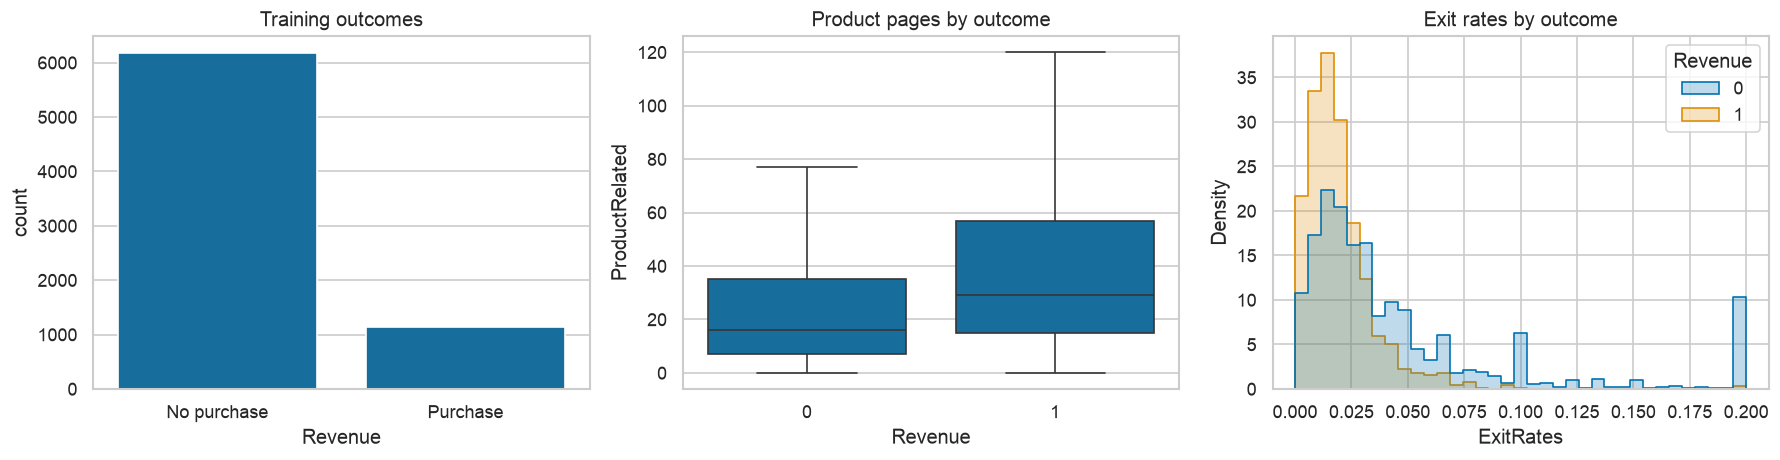

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=train, x="Revenue", ax=axes[0])
axes[0].set_xticks([0, 1], ["No purchase", "Purchase"])
axes[0].set_title("Training outcomes")
sns.boxplot(data=train, x="Revenue", y="ProductRelated", showfliers=False, ax=axes[1])
axes[1].set_title("Product pages by outcome")
sns.histplot(data=train, x="ExitRates", hue="Revenue", bins=35,
             stat="density", common_norm=False, element="step", ax=axes[2])
axes[2].set_title("Exit rates by outcome")
fig.tight_layout()
fig.savefig(FIG + "01_outcome_and_activity.png", bbox_inches="tight")
plt.show()

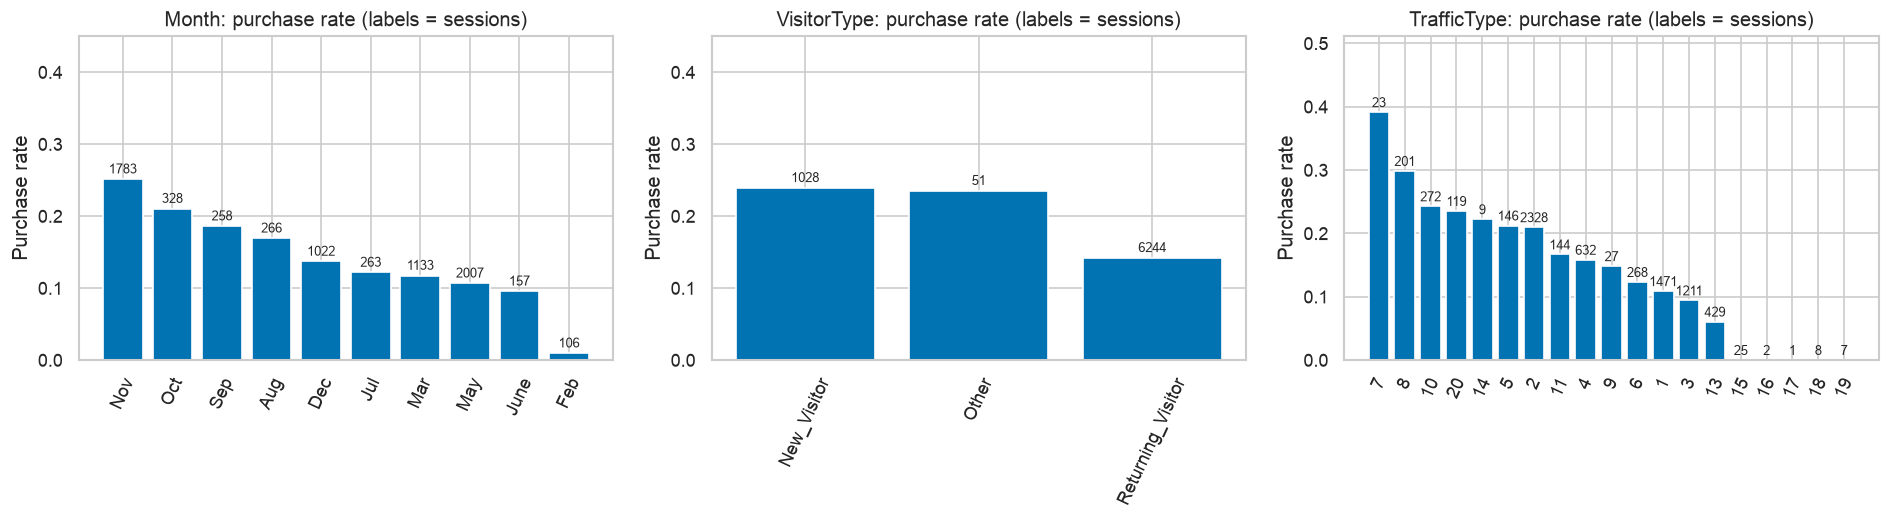

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for column, ax in zip(["Month", "VisitorType", "TrafficType"], axes):
    rates = train.groupby(column)["Revenue"].agg(["mean", "size"])
    rates = rates.sort_values("mean", ascending=False)
    ax.bar(rates.index.astype(str), rates["mean"])
    for position, count in enumerate(rates["size"]):
        ax.text(position, rates["mean"].iloc[position] + 0.008,
                str(count), ha="center", fontsize=8)
    ax.set_title(column + ": purchase rate (labels = sessions)")
    ax.set_ylabel("Purchase rate")
    ax.set_ylim(0, max(0.45, rates["mean"].max() + 0.12))
    ax.tick_params(axis="x", rotation=65)
fig.tight_layout()
fig.savefig(FIG + "02_category_purchase_rates.png", bbox_inches="tight")
plt.show()

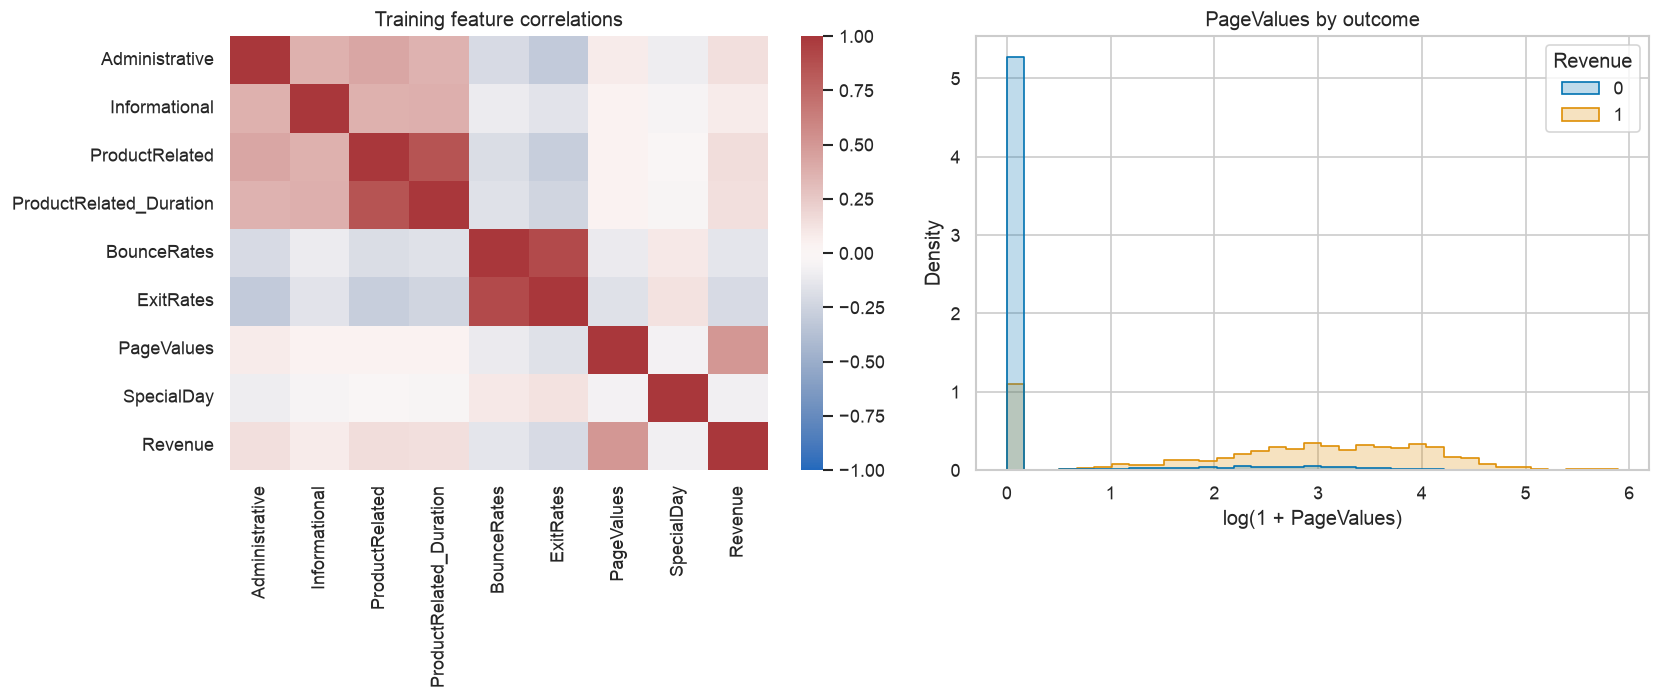

In [6]:
numeric_columns = ["Administrative", "Informational", "ProductRelated",
                   "ProductRelated_Duration", "BounceRates", "ExitRates",
                   "PageValues", "SpecialDay", "Revenue"]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(train[numeric_columns].corr(), cmap="vlag", center=0,
            vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Training feature correlations")
sns.histplot(x=np.log1p(train["PageValues"]), hue=train["Revenue"],
             bins=35, stat="density", common_norm=False,
             element="step", ax=axes[1])
axes[1].set_xlabel("log(1 + PageValues)")
axes[1].set_title("PageValues by outcome")
fig.tight_layout()
fig.savefig(FIG + "03_correlations_and_page_value.png", bbox_inches="tight")
plt.show()

## 6. Feature engineering and preprocessing

Add total pages, total duration, product-page share and seconds per page. Log totals help
linear and distance-based models handle skew. These are row-level calculations and use
no target information. Related totals overlap with their components, so individual
coefficients should not be read as independent causal effects.

Encode categories separately, then align validation and test columns to training columns.
An unseen category receives zeros for that field. Keep all indicator columns for clarity;
this creates redundant columns for an unpenalized linear model, so individual coefficients
are not uniquely identified. Penalization helps stabilize them. Fit the scaler on training
data only. The source has no missing values, so no imputation step is needed here.

In [7]:
categorical_columns = ["Month", "OperatingSystems", "Browser", "Region",
                       "TrafficType", "VisitorType"]
engineered_columns = ["TotalPages", "TotalDuration", "ProductPageShare",
                      "SecondsPerPage", "LogTotalPages", "LogTotalDuration"]

for data in [train, val, test]:
    data["TotalPages"] = (
        data["Administrative"] + data["Informational"] + data["ProductRelated"]
    )
    data["TotalDuration"] = (
        data["Administrative_Duration"] + data["Informational_Duration"]
        + data["ProductRelated_Duration"]
    )
    data["ProductPageShare"] = data["ProductRelated"] / data["TotalPages"].clip(lower=1)
    data["SecondsPerPage"] = data["TotalDuration"] / data["TotalPages"].clip(lower=1)
    data["LogTotalPages"] = np.log1p(data["TotalPages"])
    data["LogTotalDuration"] = np.log1p(data["TotalDuration"])
    data[categorical_columns] = data[categorical_columns].astype(str)

y_train = train["Revenue"]
y_val = val["Revenue"]
y_test = test["Revenue"]

X_train = pd.get_dummies(
    train.drop(columns="Revenue"), columns=categorical_columns, dtype=int
)
X_val = pd.get_dummies(
    val.drop(columns="Revenue"), columns=categorical_columns, dtype=int
)
X_test = pd.get_dummies(
    test.drop(columns="Revenue"), columns=categorical_columns, dtype=int
)
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
print("Encoded shapes:", X_train.shape, X_val.shape, X_test.shape)

Encoded shapes: (7323, 79) (2441, 79) (2441, 79)


## 7. Baseline and evaluation

The prior baseline gives every validation session the training purchase rate. Its AP
equals validation prevalence. At a 0.5 cutoff it predicts no purchases, illustrating why
accuracy can be misleading here.

The small helper below only calculates and records metrics. Each estimator's fitting
and prediction remain visible in the model cells. All comparison-table precision,
recall and F1 values use 0.5 until a cutoff is explicitly selected later.

In [8]:
results = {}
validation_probabilities = {}
metric_columns = ["AP", "ROC-AUC", "Log loss", "Brier", "Precision", "Recall", "F1", "Accuracy"]

def evaluate(name, actual, probability):
    predicted = (probability >= 0.5).astype(int)
    results[name] = [
        average_precision_score(actual, probability),
        roc_auc_score(actual, probability),
        log_loss(actual, probability),
        brier_score_loss(actual, probability),
        precision_score(actual, predicted, zero_division=0),
        recall_score(actual, predicted),
        f1_score(actual, predicted),
        accuracy_score(actual, predicted)
    ]
    validation_probabilities[name] = probability
    print(name, "| AP:", round(results[name][0], 4),
          "| ROC-AUC:", round(results[name][1], 4))

prior_val = np.full(len(y_val), y_train.mean())
evaluate("Prior baseline", y_val, prior_val)

Prior baseline | AP: 0.1561 | ROC-AUC: 0.5


## 8. Logistic regression

Logistic regression models purchase log odds as an additive function of its inputs.
It is fast and offers a transparent reference, but interactions must be supplied as
features. Overlapping counts, totals and indicators make individual unpenalized
coefficients unstable; inspect them as descriptions of this fit, not causal effects.

`C=np.inf` gives the unpenalized reference in the installed scikit-learn version.

Logistic regression | AP: 0.6025 | ROC-AUC: 0.8834


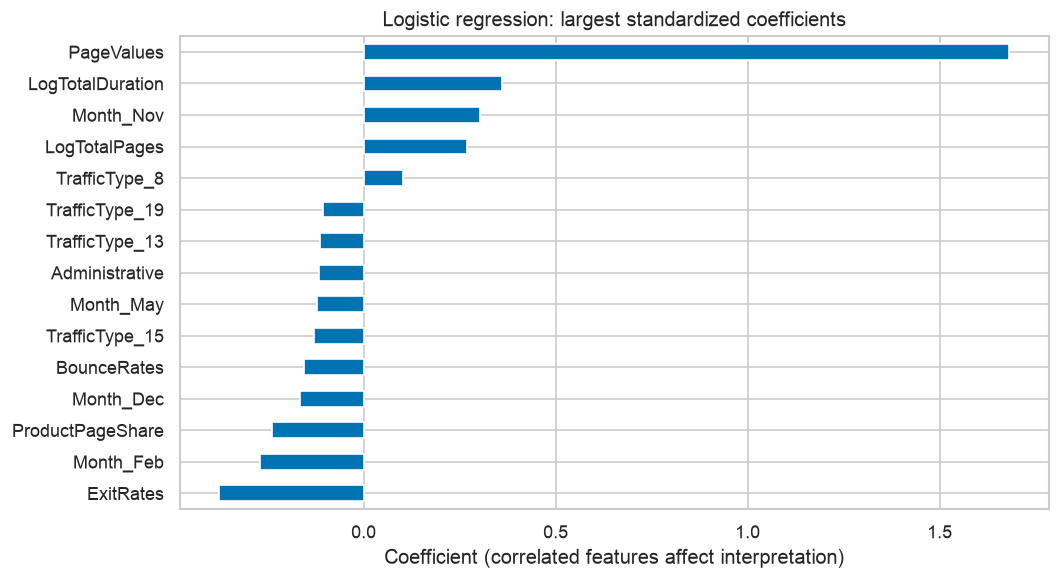

In [9]:
logistic = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=5000, tol=0.001)
logistic.fit(X_train_scaled, y_train)
logistic_val = logistic.predict_proba(X_val_scaled)[:, 1]
evaluate("Logistic regression", y_val, logistic_val)

coefficients = pd.Series(logistic.coef_[0], index=X_train.columns)
top_coefficients = coefficients.abs().nlargest(15).index
fig, ax = plt.subplots(figsize=(9, 5))
coefficients.loc[top_coefficients].sort_values().plot.barh(ax=ax)
ax.set_title("Logistic regression: largest standardized coefficients")
ax.set_xlabel("Coefficient (correlated features affect interpretation)")
fig.tight_layout()
fig.savefig(FIG + "04_logistic_coefficients.png", bbox_inches="tight")
plt.show()

## 9. Regularized linear models

For this binary target, use penalized logistic regression: **L2 (Ridge-style)** shrinks
coefficients, **L1 (Lasso-style)** can set them to zero, and **Elastic Net** combines both.
Ridge and Lasso regression estimators themselves are intended for continuous targets.

Try three values of `C`, the inverse penalty strength. Keep the value with the highest
validation AP for each penalty. This is a short validation search, not cross-validation.
L2 can retain many small effects; L1 is sparse but may choose arbitrarily among correlated
features; Elastic Net balances sparsity and stability. None automatically captures complex
nonlinear interactions.

In [10]:
best_ap = -1
for C in [0.05, 0.5, 5]:
    model = LogisticRegression(
        C=C, l1_ratio=0, solver="lbfgs", max_iter=5000, tol=0.001
    )
    model.fit(X_train_scaled, y_train)
    probability = model.predict_proba(X_val_scaled)[:, 1]
    score = average_precision_score(y_val, probability)
    print("L2 C:", C, "AP:", round(score, 4))
    if score > best_ap:
        best_ap = score
        ridge_logistic = model
ridge_val = ridge_logistic.predict_proba(X_val_scaled)[:, 1]
evaluate("L2 logistic (Ridge-style)", y_val, ridge_val)
print("Selected C:", ridge_logistic.C)

L2 C: 0.05 AP: 0.602
L2 C: 0.5 AP: 0.6025
L2 C: 5 AP: 0.6025
L2 logistic (Ridge-style) | AP: 0.6025 | ROC-AUC: 0.8834
Selected C: 5


In [11]:
best_ap = -1
for C in [0.05, 0.5, 5]:
    model = LogisticRegression(
        C=C, l1_ratio=1, solver="saga", max_iter=5000,
        tol=0.001, random_state=42
    )
    model.fit(X_train_scaled, y_train)
    probability = model.predict_proba(X_val_scaled)[:, 1]
    score = average_precision_score(y_val, probability)
    print("L1 C:", C, "AP:", round(score, 4))
    if score > best_ap:
        best_ap = score
        lasso_logistic = model
lasso_val = lasso_logistic.predict_proba(X_val_scaled)[:, 1]
evaluate("L1 logistic (Lasso-style)", y_val, lasso_val)
print("Selected C:", lasso_logistic.C)

L1 C: 0.05 AP: 0.604


L1 C: 0.5 AP: 0.604


L1 C: 5 AP: 0.6035
L1 logistic (Lasso-style) | AP: 0.604 | ROC-AUC: 0.8862
Selected C: 0.5


Elastic Net C: 0.05 AP: 0.6035


Elastic Net C: 0.5 AP: 0.6035


Elastic Net C: 5 AP: 0.6035
Elastic Net logistic | AP: 0.6035 | ROC-AUC: 0.8878
Selected C: 0.05


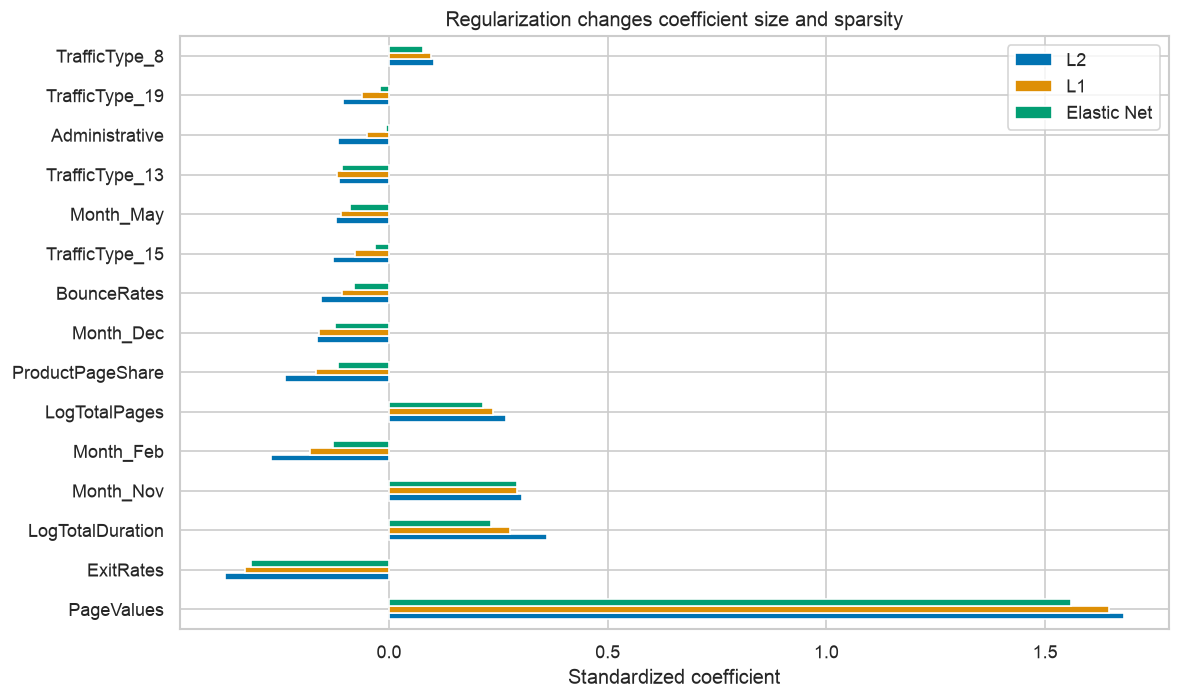

L2             79
L1             76
Elastic Net    55
Name: Nonzero coefficients, dtype: int64

In [12]:
best_ap = -1
for C in [0.05, 0.5, 5]:
    model = LogisticRegression(
        C=C, l1_ratio=0.5, solver="saga", max_iter=5000,
        tol=0.001, random_state=42
    )
    model.fit(X_train_scaled, y_train)
    probability = model.predict_proba(X_val_scaled)[:, 1]
    score = average_precision_score(y_val, probability)
    print("Elastic Net C:", C, "AP:", round(score, 4))
    if score > best_ap:
        best_ap = score
        elastic_logistic = model
elastic_val = elastic_logistic.predict_proba(X_val_scaled)[:, 1]
evaluate("Elastic Net logistic", y_val, elastic_val)
print("Selected C:", elastic_logistic.C)

coefficient_table = pd.DataFrame({
    "L2": ridge_logistic.coef_[0],
    "L1": lasso_logistic.coef_[0],
    "Elastic Net": elastic_logistic.coef_[0]
}, index=X_train.columns)
top_features = coefficient_table.abs().max(axis=1).nlargest(15).index
fig, ax = plt.subplots(figsize=(10, 6))
coefficient_table.loc[top_features].plot.barh(ax=ax)
ax.set_title("Regularization changes coefficient size and sparsity")
ax.set_xlabel("Standardized coefficient")
fig.tight_layout()
fig.savefig(FIG + "05_regularization_coefficients.png", bbox_inches="tight")
plt.show()
display((coefficient_table.abs() > 0.000001).sum().rename("Nonzero coefficients"))

## 10. K-nearest neighbors

KNN averages outcomes of nearby sessions. Scaling is essential when counts, rates and
durations share a distance calculation. It is easy to understand and has no complex
training process, but irrelevant features and many indicator columns weaken distances.
Prediction also needs the training examples and becomes expensive as data grow.

In [13]:
knn = KNeighborsClassifier(n_neighbors=25, weights="distance", n_jobs=2)
knn.fit(X_train_scaled, y_train)
knn_val = knn.predict_proba(X_val_scaled)[:, 1]
evaluate("KNN", y_val, knn_val)

KNN | AP: 0.436 | ROC-AUC: 0.7844


## 11. Multilayer perceptron

An MLP can learn nonlinear interactions from scaled inputs. It is flexible, but is
sensitive to regularization, optimization and the amount of data. The loss curve checks
optimization progress; the internal validation score used for early stopping is accuracy,
not the AP used for our external model comparison.

Early stopping reserves part of the training partition internally. The project validation
and test sets remain separate. A single random seed does not measure training variability.

MLP | AP: 0.6585 | ROC-AUC: 0.8833
Training epochs: 41


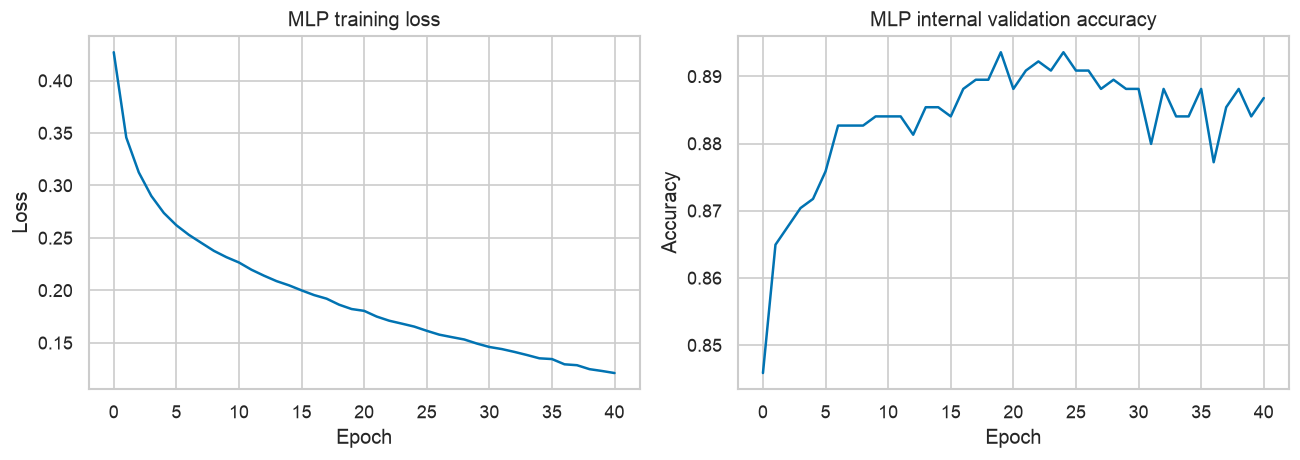

In [14]:
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32), alpha=0.001, max_iter=500,
    early_stopping=True, n_iter_no_change=20, random_state=42
)
mlp.fit(X_train_scaled, y_train)
mlp_val = mlp.predict_proba(X_val_scaled)[:, 1]
evaluate("MLP", y_val, mlp_val)
print("Training epochs:", mlp.n_iter_)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(mlp.loss_curve_)
axes[0].set_title("MLP training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[1].plot(mlp.validation_scores_)
axes[1].set_title("MLP internal validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
fig.tight_layout()
fig.savefig(FIG + "06_mlp_training.png", bbox_inches="tight")
plt.show()

## 12. Random Forest

A Random Forest averages trees trained on randomized samples and features. It captures
thresholds and interactions without scaling and is often a robust tabular baseline.
It can need many trees and may produce poorly calibrated probabilities. Minimum leaf
size limits very specific rules. Impurity importance can favor continuous or frequently
split features, so it is only an initial interpretation.

Random Forest | AP: 0.7159 | ROC-AUC: 0.9138


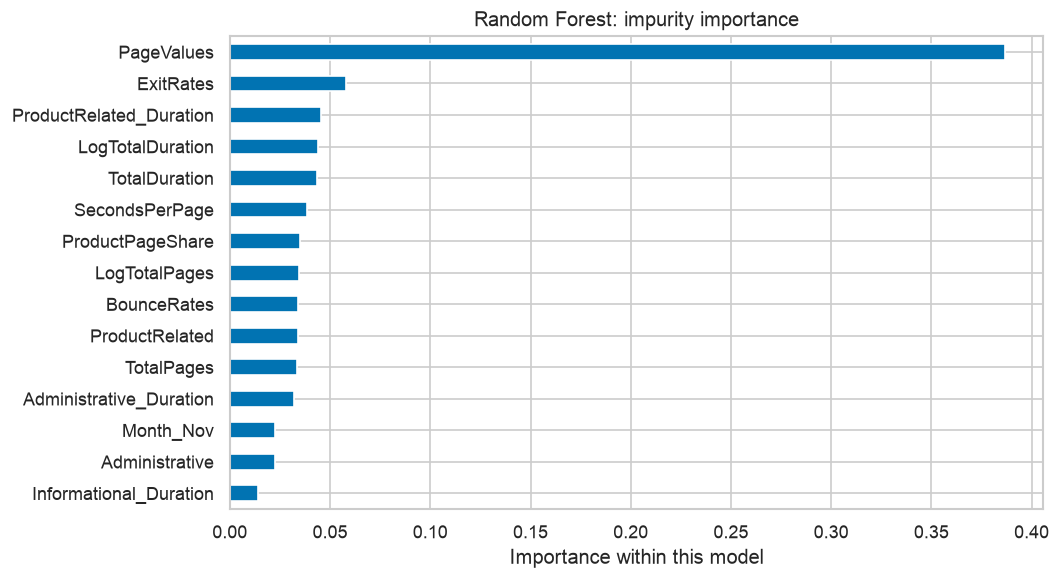

In [15]:
forest = RandomForestClassifier(
    n_estimators=250, min_samples_leaf=3, random_state=42, n_jobs=2
)
forest.fit(X_train, y_train)
forest_val = forest.predict_proba(X_val)[:, 1]
evaluate("Random Forest", y_val, forest_val)

fig, ax = plt.subplots(figsize=(9, 5))
pd.Series(forest.feature_importances_, index=X_train.columns).nlargest(15).sort_values().plot.barh(ax=ax)
ax.set_title("Random Forest: impurity importance")
ax.set_xlabel("Importance within this model")
fig.tight_layout()
fig.savefig(FIG + "07_forest_importance.png", bbox_inches="tight")
plt.show()

## 13. XGBoost

XGBoost adds regularized trees sequentially. It is effective for structured data and can
learn interactions with limited feature engineering. Depth, learning rate and tree count
work together, so a small depth search is only a modest exploration. Row and column
sampling reduce dependence on particular observations and features. Its importance
values describe this model and are not directly comparable with another library's scale.

XGBoost | AP: 0.725 | ROC-AUC: 0.9161


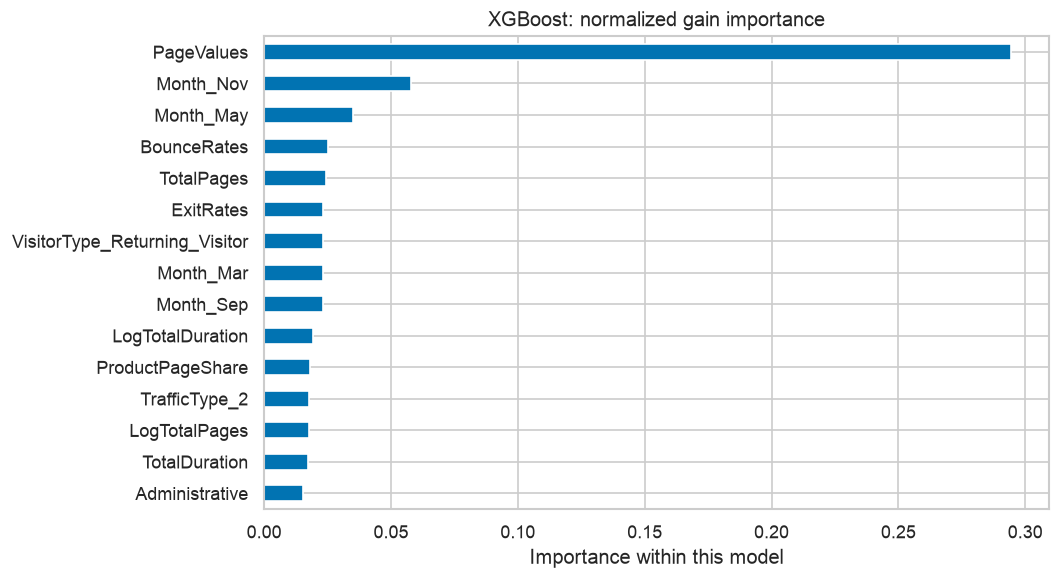

In [16]:
xgb = XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05, min_child_weight=3,
    subsample=0.85, colsample_bytree=0.85, reg_lambda=2,
    objective="binary:logistic", eval_metric="logloss", tree_method="hist",
    random_state=42, n_jobs=2
)
xgb.fit(X_train, y_train)
xgb_val = xgb.predict_proba(X_val)[:, 1]
evaluate("XGBoost", y_val, xgb_val)

fig, ax = plt.subplots(figsize=(9, 5))
pd.Series(xgb.feature_importances_, index=X_train.columns).nlargest(15).sort_values().plot.barh(ax=ax)
ax.set_title("XGBoost: normalized gain importance")
ax.set_xlabel("Importance within this model")
fig.tight_layout()
fig.savefig(FIG + "08_xgboost_importance.png", bbox_inches="tight")
plt.show()

## 14. CatBoost

CatBoost uses symmetric boosted trees and can handle categorical variables natively.
Here it uses the same one-hot inputs as the other trees to keep the code and comparison
straightforward. Native categorical handling would be a useful separate experiment;
these results do not test that advantage. CatBoost is a strong tabular candidate, but
additional tree depth can increase runtime and overfitting.

CatBoost | AP: 0.7275 | ROC-AUC: 0.9197


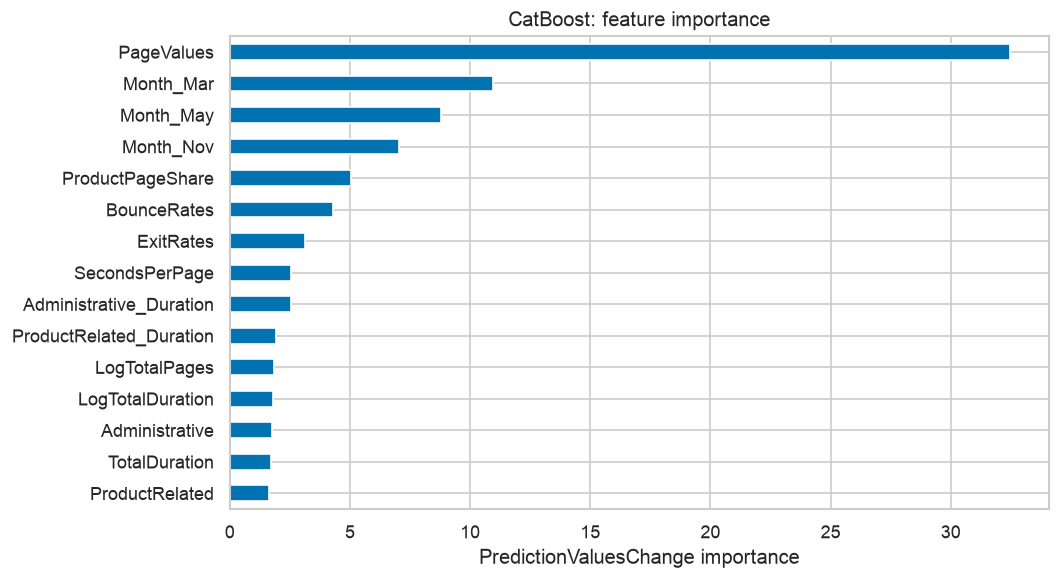

In [17]:
cat = CatBoostClassifier(
    iterations=350, depth=5, learning_rate=0.05, l2_leaf_reg=5,
    loss_function="Logloss", random_seed=42, thread_count=2,
    verbose=False, allow_writing_files=False
)
cat.fit(X_train, y_train)
cat_val = cat.predict_proba(X_val)[:, 1]
evaluate("CatBoost", y_val, cat_val)

fig, ax = plt.subplots(figsize=(9, 5))
pd.Series(cat.feature_importances_, index=X_train.columns).nlargest(15).sort_values().plot.barh(ax=ax)
ax.set_title("CatBoost: feature importance")
ax.set_xlabel("PredictionValuesChange importance")
fig.tight_layout()
fig.savefig(FIG + "09_catboost_importance.png", bbox_inches="tight")
plt.show()

## 15. LightGBM

LightGBM uses histogram-based splits and leaf-wise growth. It is efficient and can fit
complex tabular relationships. Small leaves can memorize noise, so `num_leaves` and
`min_child_samples` control capacity. Like other trees, it does not reliably extrapolate
beyond the patterns represented in training data.

LightGBM | AP: 0.7233 | ROC-AUC: 0.9174


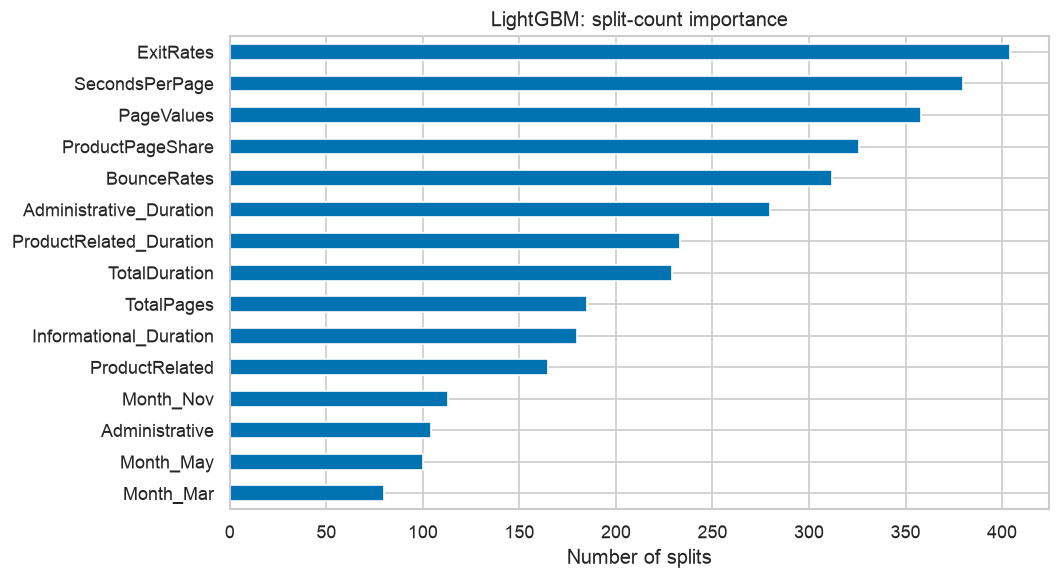

In [18]:
lgb = LGBMClassifier(
    n_estimators=300, learning_rate=0.04, num_leaves=15,
    min_child_samples=35, colsample_bytree=0.85, reg_lambda=2,
    random_state=42, n_jobs=2, verbosity=-1
)
lgb.fit(X_train, y_train)
lgb_val = lgb.predict_proba(X_val)[:, 1]
evaluate("LightGBM", y_val, lgb_val)

fig, ax = plt.subplots(figsize=(9, 5))
pd.Series(lgb.feature_importances_, index=X_train.columns).nlargest(15).sort_values().plot.barh(ax=ax)
ax.set_title("LightGBM: split-count importance")
ax.set_xlabel("Number of splits")
fig.tight_layout()
fig.savefig(FIG + "10_lightgbm_importance.png", bbox_inches="tight")
plt.show()

## 16. Hyperparameter tuning

Try two values of one important parameter per nonlinear model. Each candidate receives
the full training partition, with MLP retaining its internal early-stopping holdout.
Use validation AP to keep one candidate per family. These compact searches are practical
for a timed exercise; they do not establish each family's best possible performance.

The validation set is reused across many comparisons. Keep that selection uncertainty
in mind and use the held-out test only after all choices have been fixed.

In [19]:
best_ap = -1
for neighbors in [11, 25]:
    model = KNeighborsClassifier(n_neighbors=neighbors, weights="distance", n_jobs=2)
    model.fit(X_train_scaled, y_train)
    probability = model.predict_proba(X_val_scaled)[:, 1]
    score = average_precision_score(y_val, probability)
    print("KNN neighbors:", neighbors, "AP:", round(score, 4))
    if score > best_ap:
        best_ap = score
        knn_tuned = model
knn_tuned_val = knn_tuned.predict_proba(X_val_scaled)[:, 1]
evaluate("KNN (tuned)", y_val, knn_tuned_val)

KNN neighbors: 11 AP: 0.4252
KNN neighbors: 25 AP: 0.436
KNN (tuned) | AP: 0.436 | ROC-AUC: 0.7844


In [20]:
best_ap = -1
for alpha in [0.001, 0.01]:
    model = MLPClassifier(
        hidden_layer_sizes=(64, 32), alpha=alpha, max_iter=500,
        early_stopping=True, n_iter_no_change=20, random_state=42
    )
    model.fit(X_train_scaled, y_train)
    probability = model.predict_proba(X_val_scaled)[:, 1]
    score = average_precision_score(y_val, probability)
    print("MLP alpha:", alpha, "AP:", round(score, 4))
    if score > best_ap:
        best_ap = score
        mlp_tuned = model
mlp_tuned_val = mlp_tuned.predict_proba(X_val_scaled)[:, 1]
evaluate("MLP (tuned)", y_val, mlp_tuned_val)

MLP alpha: 0.001 AP: 0.6585


MLP alpha: 0.01 AP: 0.6586
MLP (tuned) | AP: 0.6586 | ROC-AUC: 0.8825


In [21]:
best_ap = -1
for depth in [8, 12]:
    model = RandomForestClassifier(
        n_estimators=250, max_depth=depth, min_samples_leaf=3,
        random_state=42, n_jobs=2
    )
    model.fit(X_train, y_train)
    probability = model.predict_proba(X_val)[:, 1]
    score = average_precision_score(y_val, probability)
    print("Forest depth:", depth, "AP:", round(score, 4))
    if score > best_ap:
        best_ap = score
        forest_tuned = model
forest_tuned_val = forest_tuned.predict_proba(X_val)[:, 1]
evaluate("Random Forest (tuned)", y_val, forest_tuned_val)

Forest depth: 8 AP: 0.7104


Forest depth: 12 AP: 0.72
Random Forest (tuned) | AP: 0.72 | ROC-AUC: 0.9124


In [22]:
best_ap = -1
for depth in [2, 4]:
    model = XGBClassifier(
        n_estimators=300, max_depth=depth, learning_rate=0.05,
        min_child_weight=3, subsample=0.85, colsample_bytree=0.85, reg_lambda=2,
        objective="binary:logistic", eval_metric="logloss", tree_method="hist",
        random_state=42, n_jobs=2
    )
    model.fit(X_train, y_train)
    probability = model.predict_proba(X_val)[:, 1]
    score = average_precision_score(y_val, probability)
    print("XGBoost depth:", depth, "AP:", round(score, 4))
    if score > best_ap:
        best_ap = score
        xgb_tuned = model
xgb_tuned_val = xgb_tuned.predict_proba(X_val)[:, 1]
evaluate("XGBoost (tuned)", y_val, xgb_tuned_val)

XGBoost depth: 2 AP: 0.7172


XGBoost depth: 4 AP: 0.7229
XGBoost (tuned) | AP: 0.7229 | ROC-AUC: 0.9176


In [23]:
best_ap = -1
for depth in [4, 6]:
    model = CatBoostClassifier(
        iterations=350, depth=depth, learning_rate=0.05, l2_leaf_reg=5,
        loss_function="Logloss", random_seed=42, thread_count=2,
        verbose=False, allow_writing_files=False
    )
    model.fit(X_train, y_train)
    probability = model.predict_proba(X_val)[:, 1]
    score = average_precision_score(y_val, probability)
    print("CatBoost depth:", depth, "AP:", round(score, 4))
    if score > best_ap:
        best_ap = score
        cat_tuned = model
cat_tuned_val = cat_tuned.predict_proba(X_val)[:, 1]
evaluate("CatBoost (tuned)", y_val, cat_tuned_val)

CatBoost depth: 4 AP: 0.7238


CatBoost depth: 6 AP: 0.7255
CatBoost (tuned) | AP: 0.7255 | ROC-AUC: 0.9174


In [24]:
best_ap = -1
for leaves in [7, 23]:
    model = LGBMClassifier(
        n_estimators=300, learning_rate=0.04, num_leaves=leaves,
        min_child_samples=35, colsample_bytree=0.85, reg_lambda=2,
        random_state=42, n_jobs=2, verbosity=-1
    )
    model.fit(X_train, y_train)
    probability = model.predict_proba(X_val)[:, 1]
    score = average_precision_score(y_val, probability)
    print("LightGBM leaves:", leaves, "AP:", round(score, 4))
    if score > best_ap:
        best_ap = score
        lgb_tuned = model
lgb_tuned_val = lgb_tuned.predict_proba(X_val)[:, 1]
evaluate("LightGBM (tuned)", y_val, lgb_tuned_val)

LightGBM leaves: 7 AP: 0.7177


LightGBM leaves: 23 AP: 0.7194
LightGBM (tuned) | AP: 0.7194 | ROC-AUC: 0.9158


## 17. Model comparison

Compare AP on identical validation sessions. Probability losses answer a different
question from ranking metrics. A tuned version can lose to its reference configuration;
include both in the final comparison. Small score differences on one validation split
do not demonstrate a reliable ordering between algorithms.

In [25]:
validation_results = pd.DataFrame.from_dict(
    results, orient="index", columns=metric_columns
).sort_values("AP", ascending=False)
display(validation_results.round(4))

,AP,ROC-AUC,Log loss,Brier,Precision,Recall,F1,Accuracy
CatBoost,0.7275,0.9197,0.2442,0.0740,0.6985,0.5958,0.6431,0.8968
CatBoost (tuned),0.7255,0.9174,0.2467,0.0745,0.6982,0.6010,0.6460,0.8972
XGBoost,0.7250,0.9161,0.2472,0.0742,0.7015,0.5984,0.6459,0.8976
LightGBM,0.7233,0.9174,0.2479,0.0751,0.6787,0.5932,0.6331,0.8927
XGBoost (tuned),0.7229,0.9176,0.2475,0.0746,0.7108,0.6063,0.6544,0.9000
Random Forest (tuned),0.7200,0.9124,0.2641,0.0790,0.8186,0.4619,0.5906,0.9000
LightGBM (tuned),0.7194,0.9158,0.2518,0.0759,0.6944,0.5906,0.6383,0.8955
Random Forest,0.7159,0.9138,0.2592,0.0779,0.7869,0.5039,0.6144,0.9013
MLP (tuned),0.6586,0.8825,0.3027,0.0862,0.6797,0.5459,0.6055,0.8890
MLP,0.6585,0.8833,0.2960,0.0852,0.6947,0.5197,0.5946,0.8894


## 18. Stacking

Combine a fixed Random Forest, XGBoost and LightGBM using a logistic meta-model. Three-fold
out-of-fold predictions within the training partition teach the meta-model; the base
models are then fitted on the complete training partition. The inputs are already encoded
from training categories, and no target statistics or fitted numeric scaling are used
inside this stack. The outer validation and test partitions remain outside fitting.

Stacking can combine complementary errors, but similar base models may add little. It
also increases fitting time, storage and inference work. Check whether its measured gain
justifies this additional complexity.

Stacking | AP: 0.7288 | ROC-AUC: 0.9181


,AP,ROC-AUC,Log loss,Brier,Precision,Recall,F1,Accuracy
Model,,,,,,,,
Stacking,0.7288,0.9181,0.2572,0.0757,0.7003,0.5827,0.6361,0.8959
CatBoost,0.7275,0.9197,0.2442,0.0740,0.6985,0.5958,0.6431,0.8968
CatBoost (tuned),0.7255,0.9174,0.2467,0.0745,0.6982,0.6010,0.6460,0.8972
XGBoost,0.7250,0.9161,0.2472,0.0742,0.7015,0.5984,0.6459,0.8976
LightGBM,0.7233,0.9174,0.2479,0.0751,0.6787,0.5932,0.6331,0.8927
XGBoost (tuned),0.7229,0.9176,0.2475,0.0746,0.7108,0.6063,0.6544,0.9000
Random Forest (tuned),0.7200,0.9124,0.2641,0.0790,0.8186,0.4619,0.5906,0.9000
LightGBM (tuned),0.7194,0.9158,0.2518,0.0759,0.6944,0.5906,0.6383,0.8955
Random Forest,0.7159,0.9138,0.2592,0.0779,0.7869,0.5039,0.6144,0.9013


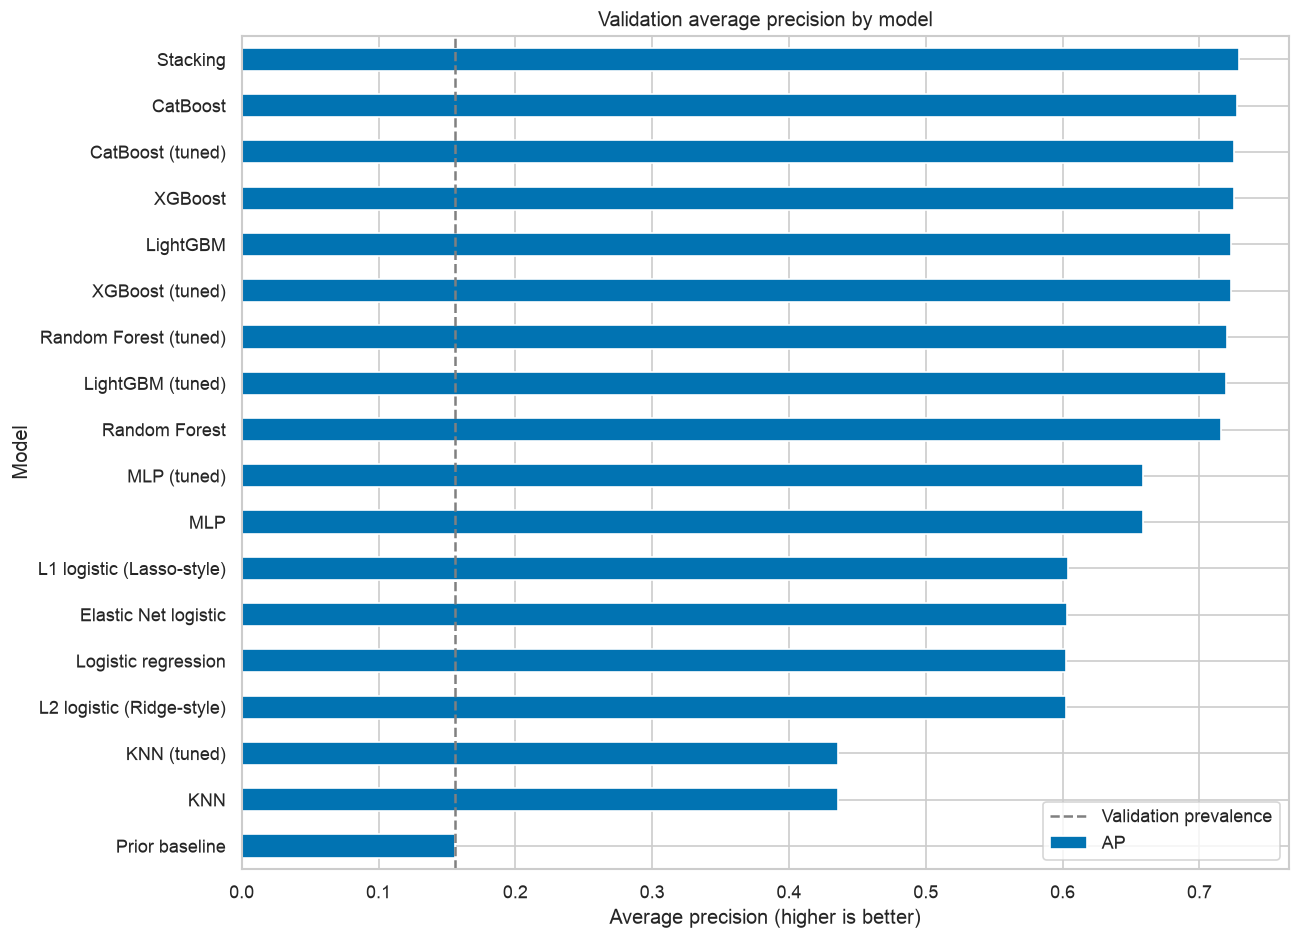

In [26]:
stack = StackingClassifier(
    estimators=[("forest", forest), ("xgb", xgb), ("lgb", lgb)],
    final_estimator=LogisticRegression(C=1, max_iter=2000),
    stack_method="predict_proba", cv=3, n_jobs=1
)
stack.fit(X_train, y_train)
stack_val = stack.predict_proba(X_val)[:, 1]
evaluate("Stacking", y_val, stack_val)

validation_results = pd.DataFrame.from_dict(
    results, orient="index", columns=metric_columns
).sort_values("AP", ascending=False)
validation_results.index.name = "Model"
validation_results.to_csv("outputs/validation_results.csv")
display(validation_results.round(4))

validation_predictions = pd.DataFrame(validation_probabilities, index=val.index)
validation_predictions.insert(0, "Actual", y_val)
validation_predictions.rename_axis("Source row").to_csv("outputs/validation_predictions.csv")

fig, ax = plt.subplots(figsize=(11, 8))
validation_results["AP"].sort_values().plot.barh(ax=ax)
ax.axvline(y_val.mean(), color="gray", linestyle="--", label="Validation prevalence")
ax.set_title("Validation average precision by model")
ax.set_xlabel("Average precision (higher is better)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG + "11_validation_comparison.png", bbox_inches="tight")
plt.show()

## 19. Feature ablation and cutoff selection

Hold the reference LightGBM settings fixed and compare original inputs, engineered
inputs, and engineered inputs without PageValues. These are diagnostic feature tests;
they are separate from the prespecified main model comparison above. This distinguishes
the contribution of the added features from a change in estimator settings.

Removing PageValues tests dependence on that one variable. It does not establish that
the remaining session summaries are available early enough for an intervention.

,Feature set,Validation AP
0,Original features,0.7189
1,With engineered features,0.7233
2,Without PageValues,0.3638


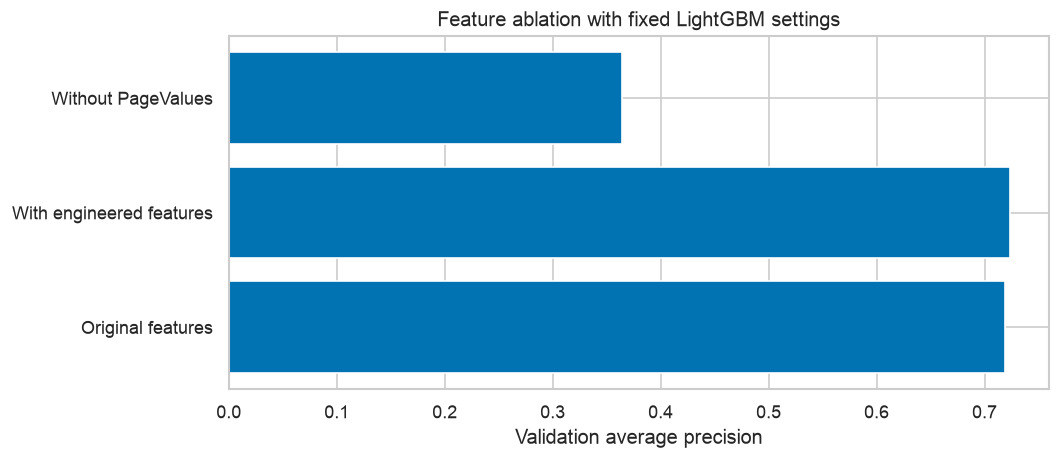

In [27]:
raw_columns = X_train.columns.drop(engineered_columns)
lgb_raw = LGBMClassifier(
    n_estimators=300, learning_rate=0.04, num_leaves=15,
    min_child_samples=35, colsample_bytree=0.85, reg_lambda=2,
    random_state=42, n_jobs=2, verbosity=-1
)
lgb_raw.fit(X_train[raw_columns], y_train)
raw_val = lgb_raw.predict_proba(X_val[raw_columns])[:, 1]

without_page_values = X_train.columns.drop("PageValues")
lgb_no_page_values = LGBMClassifier(
    n_estimators=300, learning_rate=0.04, num_leaves=15,
    min_child_samples=35, colsample_bytree=0.85, reg_lambda=2,
    random_state=42, n_jobs=2, verbosity=-1
)
lgb_no_page_values.fit(X_train[without_page_values], y_train)
no_page_values_val = lgb_no_page_values.predict_proba(X_val[without_page_values])[:, 1]

ablation = pd.DataFrame({
    "Feature set": ["Original features", "With engineered features", "Without PageValues"],
    "Validation AP": [average_precision_score(y_val, raw_val),
                      average_precision_score(y_val, lgb_val),
                      average_precision_score(y_val, no_page_values_val)]
})
ablation.to_csv("outputs/feature_ablation.csv", index=False)
display(ablation.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ablation["Feature set"], ablation["Validation AP"])
ax.set_title("Feature ablation with fixed LightGBM settings")
ax.set_xlabel("Validation average precision")
fig.tight_layout()
fig.savefig(FIG + "12_feature_ablation.png", bbox_inches="tight")
plt.show()

Choose the main-comparison AP leader below and keep its already-fitted estimator.
The explicit assignment makes the chosen model easy to inspect. If a new run changes
the ranking, update these three assignments from the validation table before proceeding.

Search a short cutoff grid for the highest validation F1. F1 treats precision and recall
symmetrically; a real application should instead use its costs or capacity constraints.
Do not refit on train plus validation here: keeping the fitted estimator unchanged also
keeps the selected cutoff attached to the same probability model.

Validation AP leader: Stacking
Selected model: Stacking


,Cutoff,Precision,Recall,F1
0,0.10,0.5166,0.8189,0.6335
1,0.15,0.5551,0.7664,0.6439
2,0.20,0.5931,0.7270,0.6533
3,0.25,0.6060,0.6903,0.6454
4,0.30,0.6277,0.6772,0.6515
5,0.35,0.6475,0.6509,0.6492
6,0.40,0.6639,0.6273,0.6451
7,0.45,0.6939,0.6010,0.6442
8,0.50,0.7003,0.5827,0.6361
9,0.55,0.7347,0.5669,0.6400


Locked cutoff: 0.2


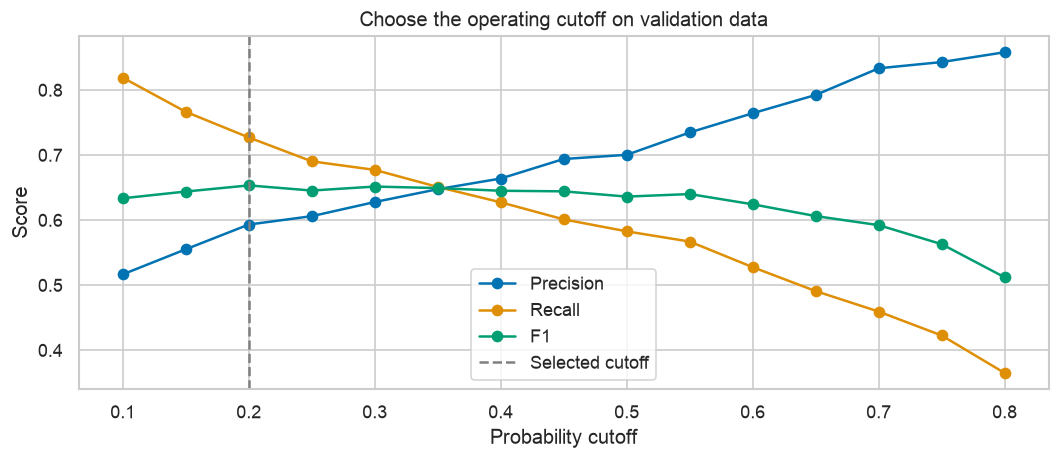

In [28]:
best_name = "Stacking"
best_model = stack
best_validation_probability = stack_val
assert best_name == validation_results.index[0], "Update the selection from the validation table."
print("Validation AP leader:", validation_results.index[0])
print("Selected model:", best_name)

cutoff_rows = []
best_f1 = -1
for cutoff in np.arange(0.10, 0.81, 0.05):
    predicted = (best_validation_probability >= cutoff).astype(int)
    precision = precision_score(y_val, predicted, zero_division=0)
    recall = recall_score(y_val, predicted)
    score = f1_score(y_val, predicted)
    cutoff_rows.append([cutoff, precision, recall, score])
    if score > best_f1:
        best_f1 = score
        best_cutoff = cutoff

cutoff_results = pd.DataFrame(cutoff_rows, columns=["Cutoff", "Precision", "Recall", "F1"])
cutoff_results.to_csv("outputs/validation_cutoffs.csv", index=False)
display(cutoff_results.round(4))
print("Locked cutoff:", round(best_cutoff, 2))
fig, ax = plt.subplots(figsize=(9, 4))
for metric in ["Precision", "Recall", "F1"]:
    ax.plot(cutoff_results["Cutoff"], cutoff_results[metric], marker="o", label=metric)
ax.axvline(best_cutoff, color="gray", linestyle="--", label="Selected cutoff")
ax.set_title("Choose the operating cutoff on validation data")
ax.set_xlabel("Probability cutoff")
ax.set_ylabel("Score")
ax.legend()
fig.tight_layout()
fig.savefig(FIG + "13_validation_cutoff.png", bbox_inches="tight")
plt.show()

## 20. Final test evaluation

Evaluate the locked estimator and cutoff on held-out sessions. Include the prior and
unpenalized logistic reference. Show the selected model at both 0.5 and the chosen cutoff
so the precision–recall trade-off is visible. AP, ROC-AUC and probability losses use
probabilities and therefore do not change when only the classification cutoff changes.

Reliability curves are diagnostic, not a probability-calibration training step. Bins with
few sessions have uncertain observed rates. Do not revise the model using test plots.

In [29]:
best_test_probability = best_model.predict_proba(X_test)[:, 1]
logistic_test_probability = logistic.predict_proba(X_test_scaled)[:, 1]
prior_test_probability = np.full(len(y_test), y_train.mean())
test_rows = []
for name, probability, cutoff in [
    ("Prior baseline", prior_test_probability, 0.5),
    ("Logistic regression", logistic_test_probability, 0.5),
    (best_name + " at 0.5", best_test_probability, 0.5),
    (best_name + " at locked cutoff", best_test_probability, best_cutoff)
]:
    predicted = (probability >= cutoff).astype(int)
    test_rows.append([
        name, cutoff, average_precision_score(y_test, probability),
        roc_auc_score(y_test, probability), log_loss(y_test, probability),
        brier_score_loss(y_test, probability),
        precision_score(y_test, predicted, zero_division=0),
        recall_score(y_test, predicted), f1_score(y_test, predicted),
        accuracy_score(y_test, predicted)
    ])
test_results = pd.DataFrame(test_rows, columns=["Model", "Cutoff"] + metric_columns)
test_results.to_csv("outputs/test_results.csv", index=False)
display(test_results.round(4))

test_predictions = pd.DataFrame({
    "Actual": y_test,
    "Selected probability": best_test_probability,
    "Selected prediction": (best_test_probability >= best_cutoff).astype(int),
    "Logistic probability": logistic_test_probability,
    "Prior probability": prior_test_probability
}, index=test.index)
test_predictions.rename_axis("Source row").to_csv("outputs/test_predictions.csv")

,Model,Cutoff,AP,ROC-AUC,Log loss,Brier,Precision,Recall,F1,Accuracy
0,Prior baseline,0.5,0.1565,0.5000,0.4338,0.1320,0.0000,0.0000,0.0000,0.8435
1,Logistic regression,0.5,0.6583,0.9042,0.2897,0.0831,0.7465,0.4241,0.5409,0.8873
2,Stacking at 0.5,0.5,0.7489,0.9335,0.2405,0.0710,0.7295,0.6283,0.6751,0.9054
3,Stacking at locked cutoff,0.2,0.7489,0.9335,0.2405,0.0710,0.6170,0.7592,0.6808,0.8886


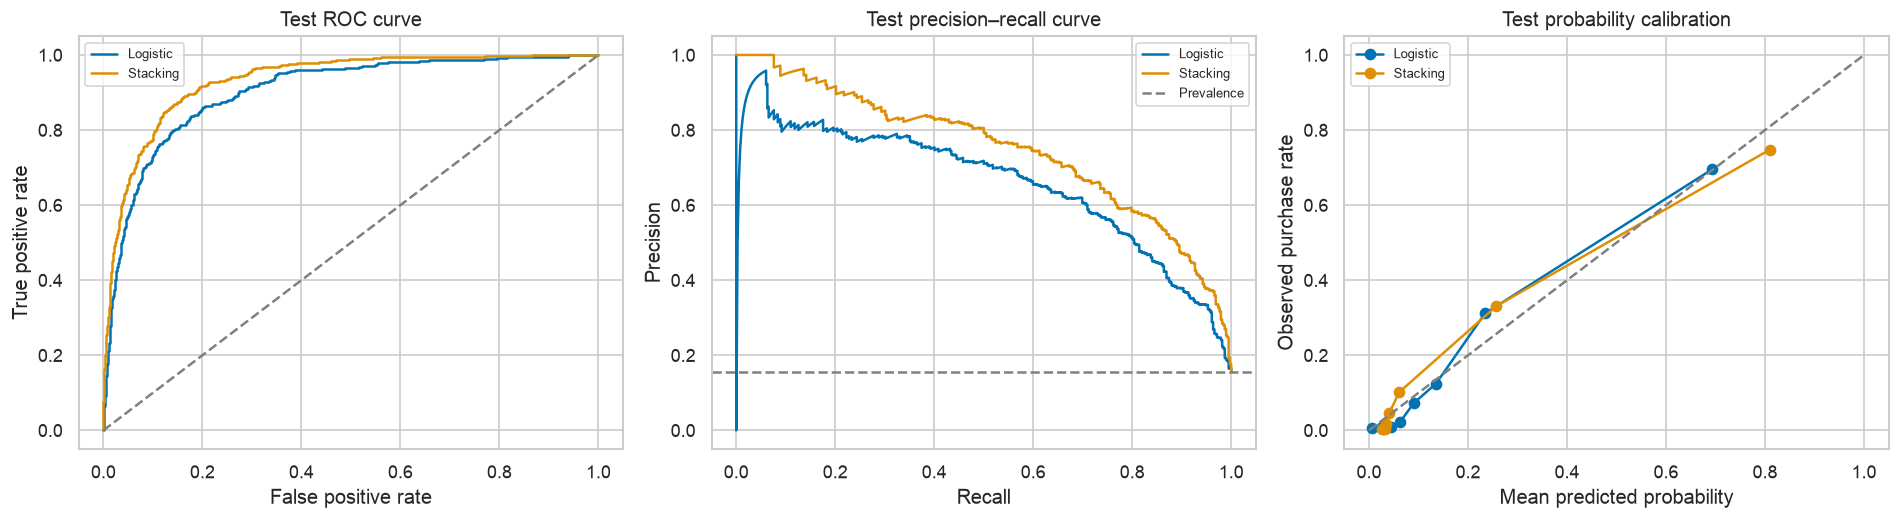

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name, probability in [("Logistic", logistic_test_probability),
                           (best_name, best_test_probability)]:
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probability)
    precision, recall, _ = precision_recall_curve(y_test, probability)
    observed, predicted = calibration_curve(y_test, probability, n_bins=8, strategy="quantile")
    axes[0].plot(false_positive_rate, true_positive_rate, label=name)
    axes[1].plot(recall, precision, label=name)
    axes[2].plot(predicted, observed, marker="o", label=name)
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(title="Test ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Prevalence")
axes[1].set(title="Test precision–recall curve", xlabel="Recall", ylabel="Precision")
axes[2].plot([0, 1], [0, 1], "--", color="gray")
axes[2].set(title="Test probability calibration", xlabel="Mean predicted probability",
            ylabel="Observed purchase rate")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG + "14_test_curves_and_calibration.png", bbox_inches="tight")
plt.show()

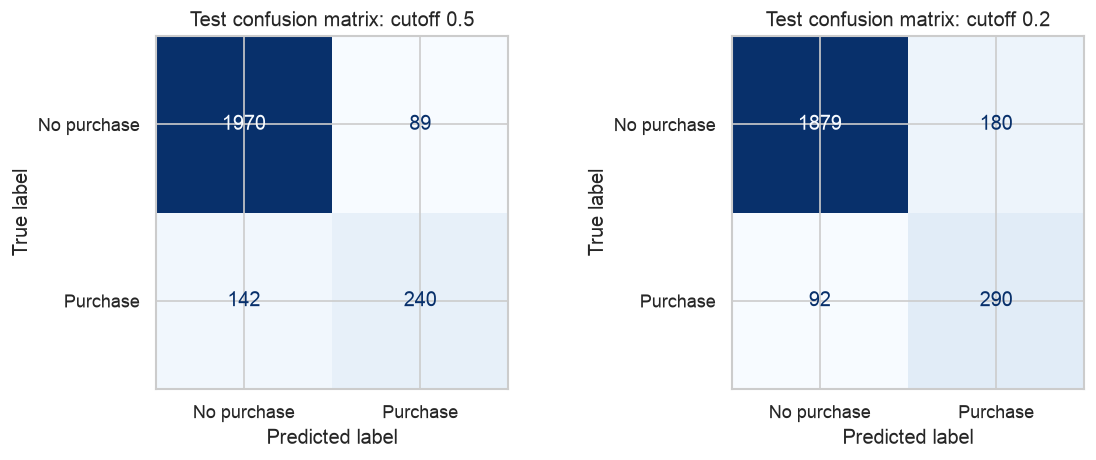

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for cutoff, ax in zip([0.5, best_cutoff], axes):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (best_test_probability >= cutoff).astype(int),
        display_labels=["No purchase", "Purchase"], cmap="Blues",
        colorbar=False, ax=ax
    )
    ax.set_title("Test confusion matrix: cutoff " + str(round(cutoff, 2)))
fig.tight_layout()
fig.savefig(FIG + "15_test_confusion_matrices.png", bbox_inches="tight")
plt.show()

## 21. Model interpretation and error analysis

Permutation importance measures the validation AP decrease when a feature column is
shuffled. It explains this fitted model, not a causal mechanism. Correlated totals and
their components can substitute for each other. Indicator columns are shuffled separately,
so this is encoded-column importance rather than whole-category importance; such shuffles
can also create unrealistic category combinations.

Test error analysis describes where the locked model makes mistakes. Show group support
alongside performance. Use these observations to design a future study, not to retune on
this test set. False positives are high-scoring non-purchases; they are not evidence that
an intervention would cause those sessions to convert.

,Feature,Mean AP decrease,Standard deviation
8,PageValues,0.5049,0.0122
7,ExitRates,0.0270,0.0060
24,Month_Nov,0.0242,0.0026
6,BounceRates,0.0219,0.0056
11,TotalPages,0.0098,0.0035
0,Administrative,0.0081,0.0010
13,ProductPageShare,0.0065,0.0016
23,Month_May,0.0050,0.0022
1,Administrative_Duration,0.0047,0.0022
5,ProductRelated_Duration,0.0035,0.0006


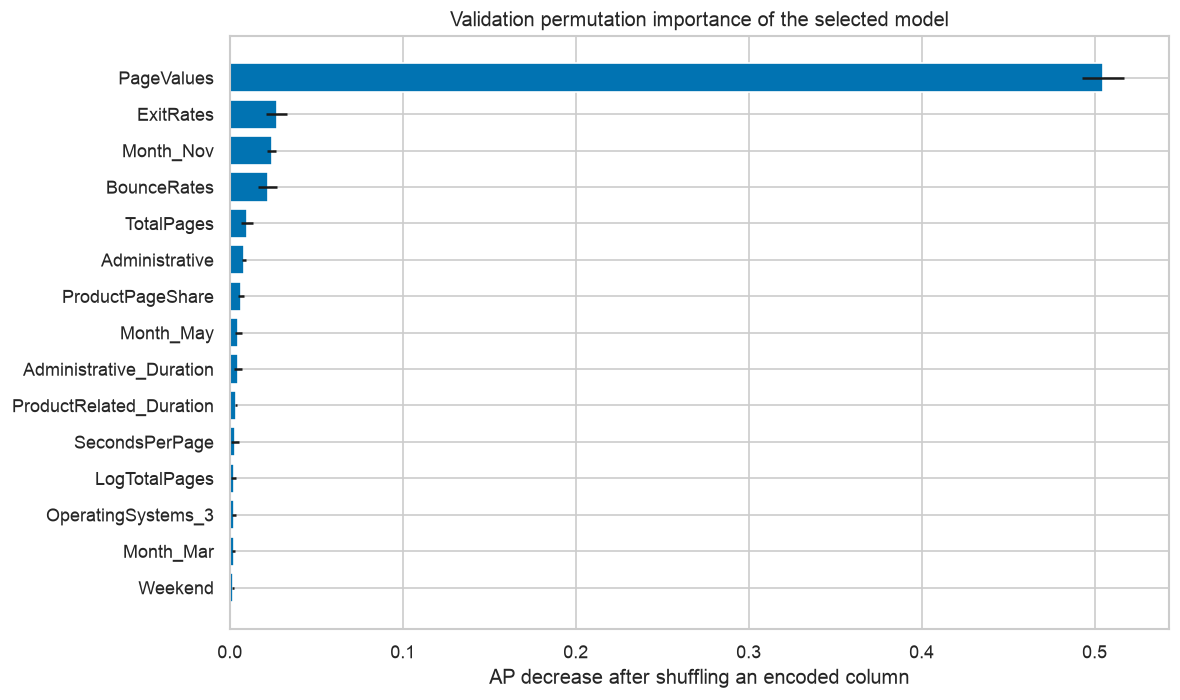

In [32]:
permutation = permutation_importance(
    best_model, X_val, y_val, scoring="average_precision",
    n_repeats=5, random_state=42, n_jobs=1
)
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Mean AP decrease": permutation.importances_mean,
    "Standard deviation": permutation.importances_std
}).sort_values("Mean AP decrease", ascending=False)
importance.to_csv("outputs/permutation_importance.csv", index=False)
display(importance.head(15).round(4))
top_importance = importance.head(15).sort_values("Mean AP decrease")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_importance["Feature"], top_importance["Mean AP decrease"],
        xerr=top_importance["Standard deviation"])
ax.set_title("Validation permutation importance of the selected model")
ax.set_xlabel("AP decrease after shuffling an encoded column")
fig.tight_layout()
fig.savefig(FIG + "16_permutation_importance.png", bbox_inches="tight")
plt.show()

,ProductRelated,PageValues,ExitRates
Outcome,,,
Correct,16.0,0.000000,0.026748
False negative,33.0,0.000000,0.024405
False positive,42.5,14.815891,0.017569


,Month,VisitorType,ProductRelated,PageValues,Probability,Revenue
12088,Nov,Other,15,69.713214,0.934576,0
1424,Mar,New_Visitor,16,20.261557,0.933245,0
11886,Nov,Returning_Visitor,20,41.134331,0.921060,0
6054,Jul,Returning_Visitor,6,63.553377,0.918305,0
5773,Oct,New_Visitor,62,246.758590,0.906861,0


,Month,VisitorType,ProductRelated,PageValues,Probability,Revenue
7600,Nov,Returning_Visitor,3,0.0,0.027636,1
10615,Nov,Returning_Visitor,3,0.0,0.029061,1
9042,Dec,Returning_Visitor,12,0.0,0.032899,1
8306,Dec,Returning_Visitor,33,0.0,0.033306,1
9225,Dec,New_Visitor,17,0.0,0.034464,1


,Field,Group,Sessions,Purchases,Purchase rate,AP,Precision,Recall
0,VisitorType,New_Visitor,344,97,0.2820,0.8960,0.8721,0.7732
1,VisitorType,Other,13,0,0.0000,NaN,0.0000,0.0000
2,VisitorType,Returning_Visitor,2084,285,0.1368,0.6783,0.5614,0.7544
3,Month,Aug,73,14,0.1918,0.7274,0.6667,0.7143
4,Month,Dec,343,37,0.1079,0.7582,0.6429,0.7297
5,Month,Feb,37,0,0.0000,NaN,0.0000,0.0000
6,Month,Jul,79,15,0.1899,0.6713,0.6429,0.6000
7,Month,June,60,6,0.1000,0.6592,0.3750,0.5000
8,Month,Mar,360,33,0.0917,0.8535,0.7273,0.9697
9,Month,May,655,79,0.1206,0.7988,0.5656,0.8734


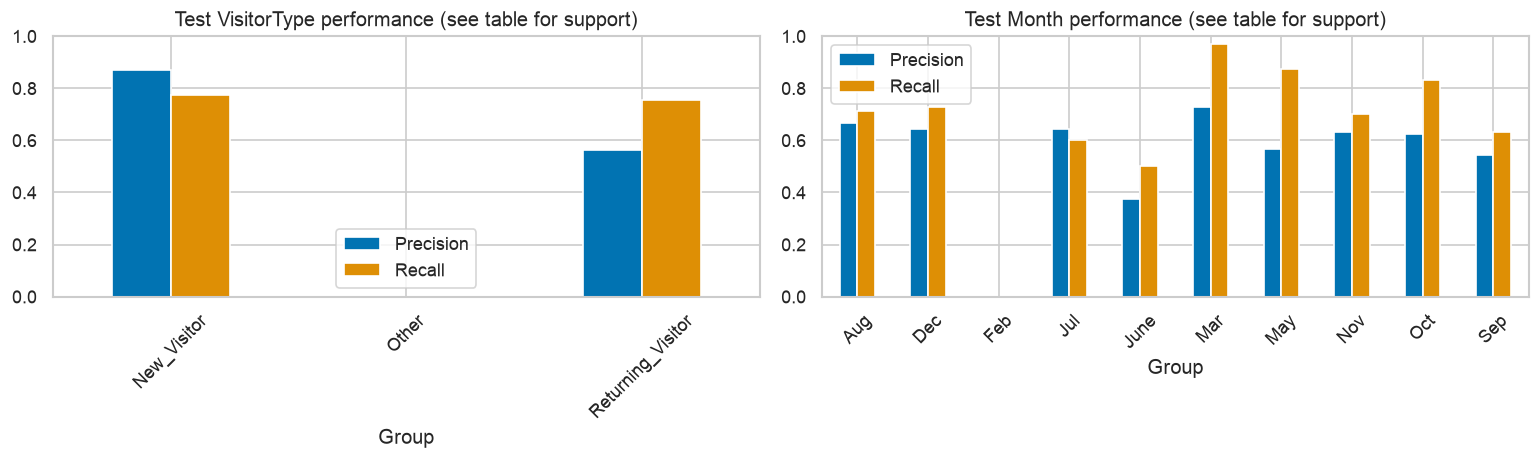

In [33]:
errors = test.copy()
errors["Probability"] = best_test_probability
errors["Predicted"] = (best_test_probability >= best_cutoff).astype(int)
errors["Outcome"] = "Correct"
errors.loc[(errors["Revenue"] == 0) & (errors["Predicted"] == 1), "Outcome"] = "False positive"
errors.loc[(errors["Revenue"] == 1) & (errors["Predicted"] == 0), "Outcome"] = "False negative"
display(errors.groupby("Outcome")[["ProductRelated", "PageValues", "ExitRates"]].median())
display(errors[errors["Outcome"] == "False positive"].nlargest(5, "Probability")[[
    "Month", "VisitorType", "ProductRelated", "PageValues", "Probability", "Revenue"
]])
display(errors[errors["Outcome"] == "False negative"].nsmallest(5, "Probability")[[
    "Month", "VisitorType", "ProductRelated", "PageValues", "Probability", "Revenue"
]])

group_rows = []
for column in ["VisitorType", "Month"]:
    for group, data in errors.groupby(column):
        ap = np.nan
        if data["Revenue"].nunique() == 2:
            ap = average_precision_score(data["Revenue"], data["Probability"])
        group_rows.append([
            column, group, len(data), data["Revenue"].sum(), data["Revenue"].mean(), ap,
            precision_score(data["Revenue"], data["Predicted"], zero_division=0),
            recall_score(data["Revenue"], data["Predicted"], zero_division=0)
        ])
group_results = pd.DataFrame(group_rows, columns=[
    "Field", "Group", "Sessions", "Purchases", "Purchase rate", "AP", "Precision", "Recall"
])
group_results.to_csv("outputs/group_results.csv", index=False)
display(group_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for column, ax in zip(["VisitorType", "Month"], axes):
    group_data = group_results[group_results["Field"] == column].set_index("Group")
    group_data[["Precision", "Recall"]].plot.bar(ax=ax)
    ax.set_title("Test " + column + " performance (see table for support)")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIG + "17_group_error_analysis.png", bbox_inches="tight")
plt.show()

## 22. Capacity analysis and uncertainty

At a limited review capacity, rank sessions by predicted purchase probability and select
the top fraction. Report precision, share of purchases captured and lift over test
prevalence. This is purchase propensity, not incremental marketing response: the highest
scorers may purchase without any action.

Bootstrap test rows to estimate sampling uncertainty with the fitted model and cutoff
held fixed. These intervals assume independent session records. They exclude uncertainty
from model selection, retraining, unknown repeated visitors and future distribution shift.
They are not proof that one algorithm is better than another.

,Selection share,Selected sessions,Purchases,Precision,Recall,Lift
0,0.01,25,25,1.0000,0.0654,6.3901
1,0.05,123,106,0.8618,0.2775,5.5069
2,0.10,245,193,0.7878,0.5052,5.0338
3,0.20,489,294,0.6012,0.7696,3.8419
4,0.30,733,345,0.4707,0.9031,3.0076


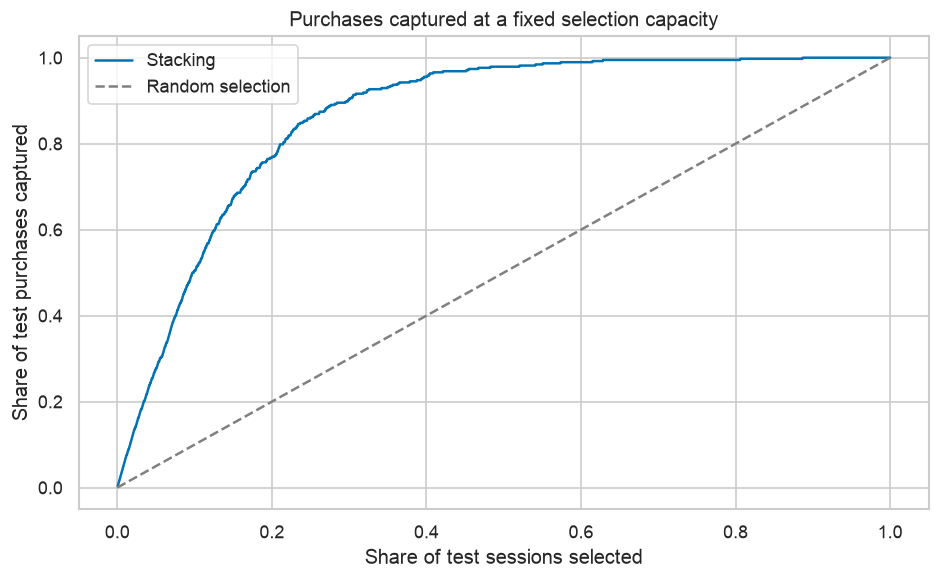

In [34]:
ranked_outcomes = y_test.to_numpy()[np.argsort(-best_test_probability)]
capacity_rows = []
for share in [0.01, 0.05, 0.10, 0.20, 0.30]:
    count = max(1, int(np.ceil(len(y_test) * share)))
    purchases = ranked_outcomes[:count].sum()
    precision = purchases / count
    recall = purchases / y_test.sum()
    lift = precision / y_test.mean()
    capacity_rows.append([share, count, purchases, precision, recall, lift])
capacity_results = pd.DataFrame(capacity_rows, columns=[
    "Selection share", "Selected sessions", "Purchases", "Precision", "Recall", "Lift"
])
capacity_results.to_csv("outputs/capacity_results.csv", index=False)
display(capacity_results.round(4))

cumulative_recall = np.cumsum(ranked_outcomes) / y_test.sum()
selection_share = np.arange(1, len(y_test) + 1) / len(y_test)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(selection_share, cumulative_recall, label=best_name)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random selection")
ax.set(title="Purchases captured at a fixed selection capacity",
       xlabel="Share of test sessions selected", ylabel="Share of test purchases captured")
ax.legend()
fig.tight_layout()
fig.savefig(FIG + "18_capacity_curve.png", bbox_inches="tight")
plt.show()

In [35]:
rng = np.random.default_rng(42)
actual = y_test.to_numpy()
bootstrap_rows = []
for repeat in range(500):
    sample = rng.choice(len(actual), size=len(actual), replace=True)
    sample_actual = actual[sample]
    sample_probability = best_test_probability[sample]
    sample_predicted = (sample_probability >= best_cutoff).astype(int)
    bootstrap_rows.append([
        average_precision_score(sample_actual, sample_probability),
        roc_auc_score(sample_actual, sample_probability),
        f1_score(sample_actual, sample_predicted)
    ])
bootstrap_results = pd.DataFrame(bootstrap_rows, columns=["AP", "ROC-AUC", "F1"])
intervals = bootstrap_results.quantile([0.025, 0.975]).T
intervals.columns = ["Lower 95%", "Upper 95%"]
intervals.insert(0, "Test estimate", [
    average_precision_score(y_test, best_test_probability),
    roc_auc_score(y_test, best_test_probability),
    f1_score(y_test, (best_test_probability >= best_cutoff).astype(int))
])
intervals.index.name = "Metric"
intervals.to_csv("outputs/test_intervals.csv")
display(intervals.round(4))

,Test estimate,Lower 95%,Upper 95%
Metric,,,
AP,0.7489,0.7091,0.7943
ROC-AUC,0.9335,0.9211,0.9472
F1,0.6808,0.6472,0.7166


## 23. Results and conclusion

Use the measured tables below to summarize the selected model, improvement over the
linear reference, operating trade-off and dependence on PageValues. The reference,
tuned and stacked models are all retained in the validation comparison, including
models whose tuning did not improve AP.

The practical outcome is a session ranking and a documented operating cutoff. Deployment
would require prediction-time feature checks, a later-period test, visitor separation
where possible, and monitoring. If the goal is marketing impact, measure incremental
conversion in a randomized intervention study rather than interpreting propensity as uplift.

In [36]:
print("Selected model:", best_name)
print("Validation AP:", round(average_precision_score(y_val, best_validation_probability), 4))
print("Locked cutoff:", round(best_cutoff, 2))
print("Test AP:", round(average_precision_score(y_test, best_test_probability), 4))
print("Logistic reference test AP:", round(average_precision_score(y_test, logistic_test_probability), 4))
print("Test AP difference from logistic:", round(
    average_precision_score(y_test, best_test_probability)
    - average_precision_score(y_test, logistic_test_probability), 4
))
display(test_results.round(4))
display(ablation.round(4))
display(capacity_results.round(4))

Selected model: Stacking
Validation AP: 0.7288
Locked cutoff: 0.2
Test AP: 0.7489
Logistic reference test AP: 0.6583
Test AP difference from logistic: 0.0906


,Model,Cutoff,AP,ROC-AUC,Log loss,Brier,Precision,Recall,F1,Accuracy
0,Prior baseline,0.5,0.1565,0.5000,0.4338,0.1320,0.0000,0.0000,0.0000,0.8435
1,Logistic regression,0.5,0.6583,0.9042,0.2897,0.0831,0.7465,0.4241,0.5409,0.8873
2,Stacking at 0.5,0.5,0.7489,0.9335,0.2405,0.0710,0.7295,0.6283,0.6751,0.9054
3,Stacking at locked cutoff,0.2,0.7489,0.9335,0.2405,0.0710,0.6170,0.7592,0.6808,0.8886


,Feature set,Validation AP
0,Original features,0.7189
1,With engineered features,0.7233
2,Without PageValues,0.3638


,Selection share,Selected sessions,Purchases,Precision,Recall,Lift
0,0.01,25,25,1.0000,0.0654,6.3901
1,0.05,123,106,0.8618,0.2775,5.5069
2,0.10,245,193,0.7878,0.5052,5.0338
3,0.20,489,294,0.6012,0.7696,3.8419
4,0.30,733,345,0.4707,0.9031,3.0076


### What the results show

- Tree ensembles rank purchases better than the linear and KNN references on this
  validation split. Stacking leads, but its advantage over CatBoost is small; that alone
  does not establish a worthwhile deployment gain or a reliable algorithm ranking.
- Lowering the cutoff from 0.5 increases purchase recall while reducing precision.
  The modest F1 change should be weighed against the larger number of non-purchases flagged.
- The fixed LightGBM ablation shows a small benefit from the engineered features and a
  substantial loss when PageValues is removed. Permutation importance also highlights
  PageValues. The model's usefulness therefore depends heavily on when this field is available.
- Selecting the top 10% of test sessions captures about half the purchases. This supports
  the value of the ranking at limited capacity, but does not measure incremental conversion
  from an intervention.

These observations describe the saved run. Update the written interpretation if you
change the data, features, split or model settings.

## 24. Presentation Q&A and saved outputs

**Why AP instead of accuracy?** Purchases are uncommon. AP summarizes precision–recall
ranking across cutoffs; read it alongside prevalence and the desired operating capacity.
ROC-AUC complements AP but can look strong even when many flagged sessions do not purchase.

**Why include Ridge and Lasso?** Their classification counterparts are L2- and L1-penalized
logistic regression. They show whether shrinkage or sparse coefficients help the linear
reference. Ordinary Ridge and Lasso regressors are not the natural probability models here.

**Why no class balancing?** AP and a selected cutoff address evaluation and the operating
trade-off without changing the training distribution. Class weights are a reasonable
additional experiment, but can change calibration and still require validation.

**What did feature engineering add?** Read the fixed-estimator ablation. Added totals may
help an additive model more than a tree, which can already model nonlinear thresholds.
The ablation reports the measured result without assuming that more features must help.

**Is PageValues leakage?** It is target-associated, but association alone does not prove
leakage. Its calculation and availability at the intended prediction time must be audited.
Removing it measures sensitivity to that field; it does not validate an early-session use case.

**Why not refit using validation data?** The cutoff was chosen for the training-fitted model.
Keeping that model fixed gives a clean test of the complete selected procedure. A production
refit would need a fresh calibration or cutoff-validation plan.

**Does stacking always improve results?** No. Similar base learners can make similar errors.
Compare its validation AP with individual models and consider the extra operational cost.

**Are the winning settings globally optimal?** No. Each nonlinear search changes one
parameter over two values. Many validation comparisons also create selection optimism.
Nested cross-validation would estimate the complete selection process more thoroughly,
but is outside this compact exercise.

**Can the probabilities be used as purchase rates?** Check Brier score, log loss and the
reliability curve. A ranking can be useful while its probabilities remain miscalibrated.
Any calibration should be fitted on separate training-side data, not this final test set.

**What do error groups mean?** They show descriptive differences on this split. Small
groups have noisy rates, and visitor categories do not establish demographic fairness.

**What should happen next?** Define the prediction time and intervention, validate on
future sessions, then test whether acting on the scores improves business outcomes.

The `outputs` directory contains comparison tables, row-level predictions, split
assignments, cutoff results, ablations, uncertainty estimates and all 18 notebook plots.
The downloaded CSV is unchanged. The practice notebook is separate from this reference.

### References

- [Kaggle: Online Shoppers Intention](https://www.kaggle.com/datasets/henrysue/online-shoppers-intention)
- Sakar, C. & Kastro, Y. (2018). [Online Shoppers Purchasing Intention Dataset](https://doi.org/10.24432/C5F88Q).
  UCI Machine Learning Repository. Original dataset license: Creative Commons Attribution 4.0.
- `dataset_source.json` records the download provenance; `data_dictionary.csv` describes the fields.